In [1]:
train_data = ["I do not like computer science",
         "ok, I will like computer science",
         "may be in a year I will like computer science",
         "I was lying, I will not like computer science",
        ]
# 0:Negative, 1:Positive
train_label = [0, 1, 1, 0]

test_data = ["I like computer science", "I am not liking computer science"]
test_label = [1, 0]

In [2]:
# Text preprocessing to create vocabulary and one-hot encoded inputs
import re

# 1. Tokenize train_data
def tokenize(text):
    return re.findall(r'\w+', text.lower())

tokenized_train = [tokenize(sent) for sent in train_data]

# 2. Build unique vocabulary
vocabulary = sorted(list(set(word for sent in tokenized_train for word in sent)))
print("Vocabulary:", vocabulary)
print("Vocabulary Size:", len(vocabulary))

# 3. Create One-Hot Encoded Representation
def one_hot_encode(tokens, vocab):
    vector = [0] * len(vocab)
    for token in tokens:
        if token in vocab:
            idx = vocab.index(token)
            vector[idx] = 1
    return vector

one_hot_encoded_data = [one_hot_encode(tokens, vocabulary) for tokens in tokenized_train]

print("\nOne-hot encoded data:")
for sent, encoded in zip(train_data, one_hot_encoded_data):
    print(f"{sent} -> {encoded}")

Vocabulary: ['a', 'be', 'computer', 'do', 'i', 'in', 'like', 'lying', 'may', 'not', 'ok', 'science', 'was', 'will', 'year']
Vocabulary Size: 15

One-hot encoded data:
I do not like computer science -> [0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0]
ok, I will like computer science -> [0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0]
may be in a year I will like computer science -> [1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1]
I was lying, I will not like computer science -> [0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0]


In [7]:
def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

In [5]:
import numpy as np

# Prepare input matrix x and target labels y
x = np.array(one_hot_encoded_data) # shape: (4, 15)
y = np.array(train_label).reshape(-1, 1) # shape: (4, 1)

# Set random seed for reproducibility
np.random.seed(42)

# 1. Dimensions
vocab_size = x.shape[1] # 15
embedding_dim = 4      # Choose an embedding dimension (e.g., 4)

# 2. Weights and Biases Initialization
# Embedding Matrix E
E = np.random.randn(vocab_size, embedding_dim)

# Layer 1: 2 nodes
W1 = np.random.randn(embedding_dim, 2)
b1 = np.zeros((1, 2))

# Layer 2: 3 nodes
W2 = np.random.randn(2, 3)
b2 = np.zeros((1, 3))

# Output Layer: 1 node (since we have a binary classification task)
W_out = np.random.randn(3, 1)
b_out = np.zeros((1, 1))

# Forward Pass Function
def forward(x):
    # Embedding step: x * E
    embedded = np.dot(x, E)

    # Layer 1: Input to 2 nodes (using sigmoid activation)
    z1 = np.dot(embedded, W1) + b1
    a1 = sigmoid(z1)

    # Layer 2: 2 nodes to 3 nodes
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Output Layer: 3 nodes to 1 node
    z_out = np.dot(a2, W_out) + b_out
    output = sigmoid(z_out)

    return embedded, a1, a2, output

# Run a single forward pass demo
embedded, a1, a2, predictions = forward(x)
print("Predictions for the 4 sentences:")
print(predictions)
print("\nActual Labels:")
print(y)

Predictions for the 4 sentences:
[[0.24880762]
 [0.27331728]
 [0.12790754]
 [0.13648351]]

Actual Labels:
[[0]
 [1]
 [1]
 [0]]


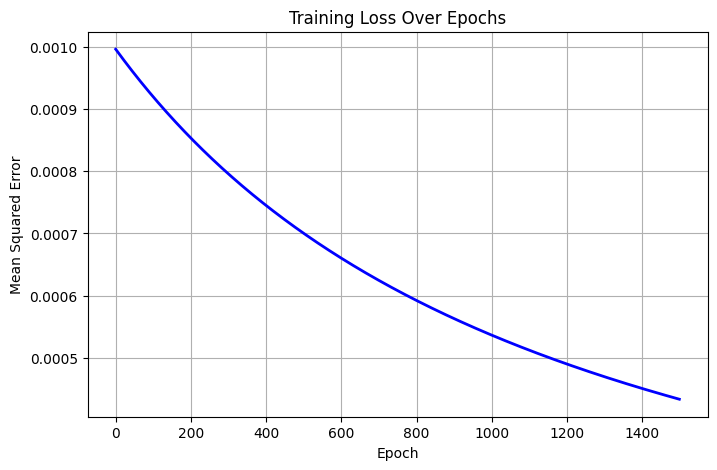

In [9]:
import matplotlib.pyplot as plt

# Training the network using Gradient Descent

# Hyperparameters
learning_rate = 0.5
epochs = 1500
losses = []

# Ensure we use training targets
y = np.array(train_label).reshape(-1, 1)

for epoch in range(epochs):
    # 1. Forward Pass
    embedded, a1, a2, predictions = forward(x)

    # Calculate mean squared error (MSE) loss
    loss = np.mean(np.square(predictions - y))
    losses.append(loss)

    # 2. Backward Pass (Backpropagation)
    m = x.shape[0]  # Number of training instances

    # Output layer gradient
    dcost_dpred = 2 * (predictions - y) / m
    dpred_dzout = sigmoid_p(np.dot(a2, W_out) + b_out)
    dloss_dzout = dcost_dpred * dpred_dzout

    dW_out = np.dot(a2.T, dloss_dzout)
    db_out = np.sum(dloss_dzout, axis=0, keepdims=True)

    # Layer 2 gradient
    dloss_da2 = np.dot(dloss_dzout, W_out.T)
    da2_dz2 = sigmoid_p(np.dot(a1, W2) + b2)
    dloss_dz2 = dloss_da2 * da2_dz2

    dW2 = np.dot(a1.T, dloss_dz2)
    db2 = np.sum(dloss_dz2, axis=0, keepdims=True)

    # Layer 1 gradient
    dloss_da1 = np.dot(dloss_dz2, W2.T)
    da1_dz1 = sigmoid_p(np.dot(embedded, W1) + b1)
    dloss_dz1 = dloss_da1 * da1_dz1

    dW1 = np.dot(embedded.T, dloss_dz1)
    db1 = np.sum(dloss_dz1, axis=0, keepdims=True)

    # Embedding layer gradient
    dloss_dembedded = np.dot(dloss_dz1, W1.T)
    dE = np.dot(x.T, dloss_dembedded)

    # 3. Parameter Updates
    W_out -= learning_rate * dW_out
    b_out -= learning_rate * db_out
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    E -= learning_rate * dE

# Plotting the loss
plt.figure(figsize=(8, 5))
plt.plot(losses, color='blue', linewidth=2)
plt.title('Training Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.grid(True)
plt.show()

In [10]:
# Evaluate the model on the test dataset

# Vectorize the test sentences using the training vocabulary
def encode_test_sentence(sentence, vocab):
    tokens = tokenize(sentence)
    vector = [0] * len(vocab)
    for token in tokens:
        if token in vocab:
            idx = vocab.index(token)
            vector[idx] = 1
    return vector

test_encoded = [encode_test_sentence(sent, vocabulary) for sent in test_data]
x_test = np.array(test_encoded)
y_test = np.array(test_label).reshape(-1, 1)

# Run forward pass on test set
_, _, _, test_predictions = forward(x_test)

# Compute predictions and accuracy
correct_predictions = 0
print("Test Set Results:")
print("=" * 60)
for i in range(len(test_data)):
    pred_val = test_predictions[i][0]
    predicted_class = 1 if pred_val >= 0.5 else 0
    actual_class = test_label[i]
    is_correct = predicted_class == actual_class
    if is_correct:
        correct_predictions += 1

    print(f"Sentence: '{test_data[i]}'")
    print(f"Probability: {pred_val:.4f} -> Predicted: {predicted_class} | Actual: {actual_class} ({'CORRECT' if is_correct else 'INCORRECT'})")
    print("-" * 60)

accuracy = (correct_predictions / len(test_data)) * 100
print(f"Final Test Accuracy: {accuracy:.2f}%")

Test Set Results:
Sentence: 'I like computer science'
Probability: 0.9719 -> Predicted: 1 | Actual: 1 (CORRECT)
------------------------------------------------------------
Sentence: 'I am not liking computer science'
Probability: 0.0248 -> Predicted: 0 | Actual: 0 (CORRECT)
------------------------------------------------------------
Final Test Accuracy: 100.00%
